# HistGradientBoosting: Fast Boosting on Fuel Economy

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `auto_mpg` | **Runs on:** CPU, about 1 minute(s)

Bin features into histograms to train boosted trees quickly and handle missing values natively.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How histogram binning speeds up split search
- Early stopping with an internal validation split
- Native handling of missing values

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Fuel economy models are rebuilt as new vehicle data arrives, so training speed matters.

**The problem.** Predict mpg with a fast boosted tree model.

**Why it matters.** Fast retraining supports frequent updates and larger searches.

**Why machine learning.** Nonlinear interactions between weight, power and year.

**Why this algorithm.** HistGradientBoosting is scikit-learn's fast boosting implementation inspired by LightGBM.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Greedy function approximation: A gradient boosting machine

- **Type:** foundational paper
- **Authors:** Friedman, J. H.
- **Year and venue:** 2001, The Annals of Statistics 29(5):1189-1232
- **DOI or URL:** https://doi.org/10.1214/aos/1013203451
- **Verification:** Crossref 2026-11-17
- **Research objective:** Cast boosting as gradient descent in function space.
- **Methodology:** Fit each new tree to the negative gradient of the loss, with shrinkage and optional subsampling.
- **Dataset:** Simulated data and a few real regression sets.
- **Main findings:** Boosted trees give accurate and robust regression and classification across loss functions.
- **Limitations:** Sequential training, sensitive to the learning rate and number of trees.

### LightGBM: A Highly Efficient Gradient Boosting Decision Tree

- **Type:** foundational paper
- **Authors:** Ke, G. et al.
- **Year and venue:** 2017, Advances in Neural Information Processing Systems 30
- **DOI or URL:** https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- **Verification:** not verified in build environment
- **Research objective:** Speed up gradient boosted trees on large data.
- **Methodology:** Histogram split finding, gradient based one side sampling and exclusive feature bundling.
- **Dataset:** Public benchmark datasets listed in the paper.
- **Main findings:** Reported much faster training than XGBoost at similar accuracy.
- **Limitations:** Leaf wise growth can overfit small datasets.

**Relationship to this notebook.** Friedman defines gradient boosting. Ke et al. describe the histogram technique used in LightGBM, which scikit-learn's implementation follows in spirit. The Ke et al. entry is not verified in the build environment. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Binning.** Each feature is mapped to at most 255 integer bins by quantiles. Split search scans bin edges only, so cost per feature is $O(\text{bins})$ per node after one pass to build gradient histograms.

**Boosting step.** Same additive model as gradient boosting: $F_m = F_{m-1} + \nu\, h_m$ where $h_m$ fits gradients and Hessians of the loss.

**Missing values.** At each split rows with missing values are sent to the side that lowers the loss.

**Limitations.** Binning loses fine resolution on very small data, and early stopping uses part of the training data.

## 5. Dataset Introduction

**Auto MPG** (Quinlan, 1993), UCI Machine Learning Repository, licence CC BY 4.0, DOI 10.24432/C5859H. 392 cars from 1970 to 1982 without missing horsepower (as shipped in `mlxtend`). Target `mpg`. Features: `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model_year`, `origin` (1 US, 2 Europe, 3 Japan). All numeric. Limit: old cars only, so conclusions do not transfer to modern vehicles.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "hist_gradient_boosting"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("auto_mpg")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: regression | target: mpg | shape: (392, 8)


,source
title,Auto MPG
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/9/auto+mpg
license,CC BY 4.0
doi,10.24432/C5859H
rows,392
features,7
limits,Cars from 1970 to 1982 only. Six rows without ...


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
0,8.0,307.0,130.0,3504.0,12.0,70.0,1.0,18.0
1,8.0,350.0,165.0,3693.0,11.5,70.0,1.0,15.0
2,8.0,318.0,150.0,3436.0,11.0,70.0,1.0,18.0
3,8.0,304.0,150.0,3433.0,12.0,70.0,1.0,16.0
4,8.0,302.0,140.0,3449.0,10.5,70.0,1.0,17.0


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (392, 8)


,columns by dtype
float64,8


,count,mean,std,min,25%,50%,75%,max
cylinders,392.0,5.472,1.706,3.0,4.000,4.00,8.000,8.0
displacement,392.0,194.412,104.644,68.0,105.000,151.00,275.750,455.0
horsepower,392.0,104.469,38.491,46.0,75.000,93.50,126.000,230.0
weight,392.0,2977.584,849.403,1613.0,2225.250,2803.50,3614.750,5140.0
acceleration,392.0,15.541,2.759,8.0,13.775,15.50,17.025,24.8
model_year,392.0,75.980,3.684,70.0,73.000,76.00,79.000,82.0
origin,392.0,1.577,0.806,1.0,1.000,1.00,2.000,3.0
mpg,392.0,23.446,7.805,9.0,17.000,22.75,29.000,46.6


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


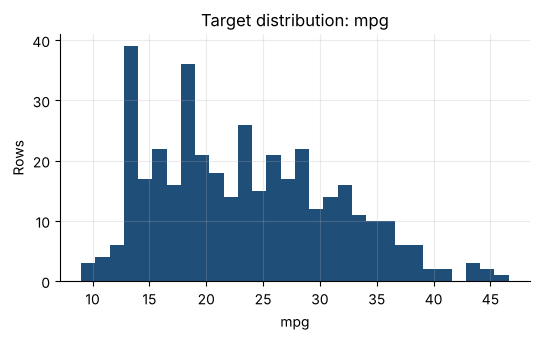

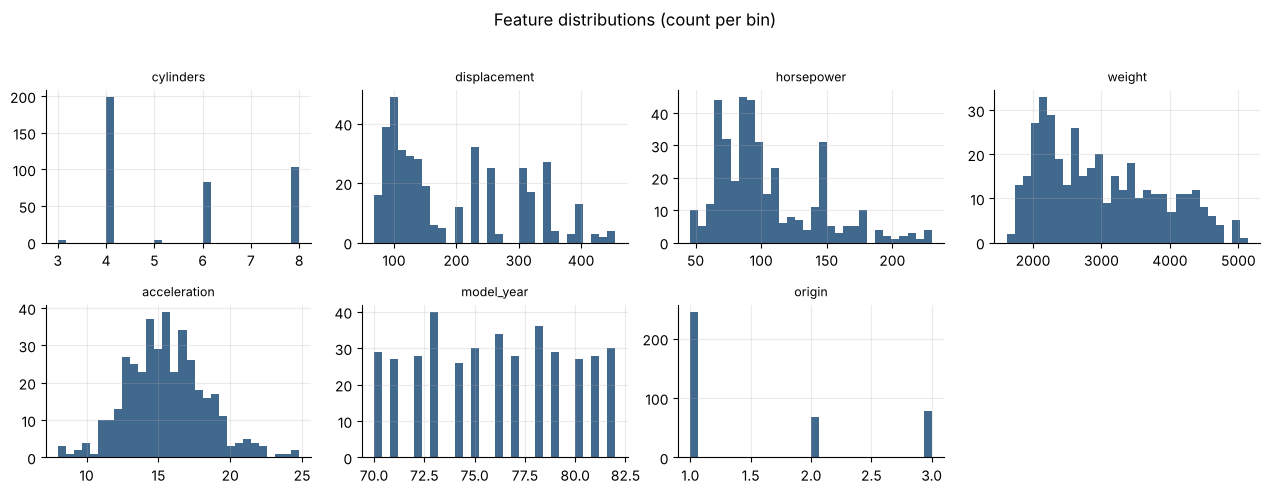

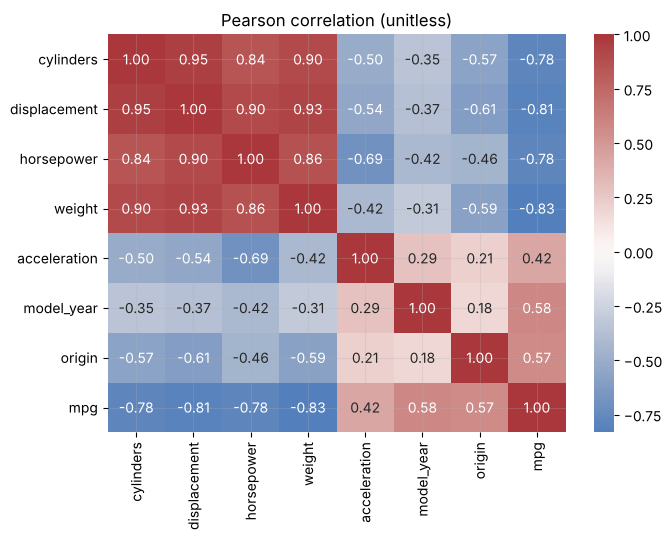

,feature,outliers,percent
0,acceleration,11,2.81
1,horsepower,10,2.55
2,cylinders,0,0.00
3,displacement,0,0.00
4,weight,0,0.00
5,model_year,0,0.00
6,origin,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=False, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 234 79 79
transformed train shape: (234, 7)


## 8. Algorithm Implementation

### 8.1 Concept

Histograms replace sorting. Instead of testing every unique value as a threshold, the algorithm tests at most a few hundred bin edges.

### 8.2 Python implementation from scratch

Not implemented from scratch: the histogram build is an engineering optimisation. We demonstrate binning with NumPy instead.

In [6]:
edges = np.quantile(X_train["weight"], np.linspace(0, 1, 11))
bins = np.digitize(X_train["weight"], edges[1:-1])
print("unique weight values:", X_train["weight"].nunique(), "-> bins:", len(np.unique(bins)))
print(pd.Series(bins).value_counts().sort_index().to_string())

unique weight values: 214 -> bins: 10
0    24
1    23
2    23
3    24
4    23
5    23
6    24
7    23
8    23
9    24


### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `max_iter` | Number of trees. |
| `learning_rate` | Shrinkage. |
| `max_leaf_nodes` | Tree size. |
| `early_stopping` | Stop on an internal validation score. |
| `l2_regularization` | Penalty on leaf values. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "RMSE"
LOWER_IS_BETTER = True
SCORING = "neg_root_mean_squared_error"
SWEEP_PARAM = "model__max_iter"
SWEEP_VALUES = [25, 50, 100, 200, 400]

def build_pipeline():
    return make_model_pipeline(X_train, HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=10, random_state=SEED), scale=False, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=8,
                              min_samples_leaf=10, random_state=42)


,RMSE,R2,MAE
model__max_iter,,,
25,3.3086,0.7737,2.5176
50,3.0994,0.8014,2.0385
100,3.2071,0.7873,2.0848
200,3.2456,0.7822,2.1536
400,3.2834,0.7771,2.2198


best model__max_iter on validation: 50
refit on train plus validation rows


## 10. Evaluation

Regression metrics: MAE (average absolute error in target units), RMSE (square root of the mean squared error, same unit, punishes large errors), R-squared (share of variance explained, can be negative on new data) and MAPE when the target is never zero.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "HistGradientBoostingRegressor": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="HistGradientBoostingRegressor", dataset="auto_mpg",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,MAE,MSE,RMSE,R2,MAPE_percent
baseline,5.8810,51.6203,7.1847,-0.0114,30.1965
HistGradientBoostingRegressor,1.8611,6.6672,2.5821,0.8694,8.6916


5-fold CV neg_root_mean_squared_error: mean -3.0318, std 0.2882
saved hist_gradient_boosting.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

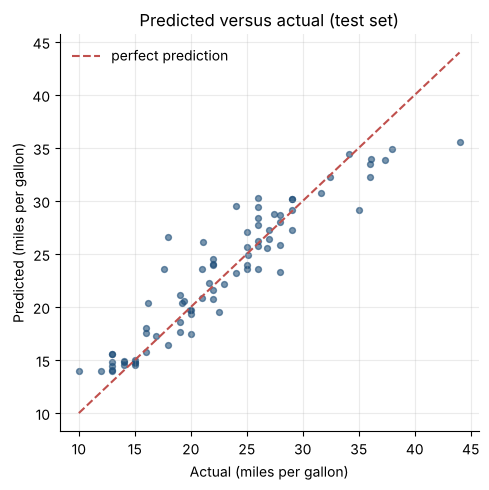

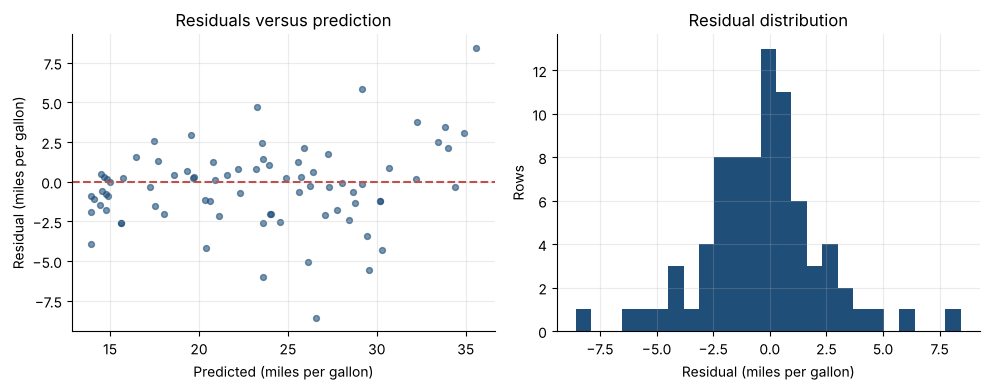

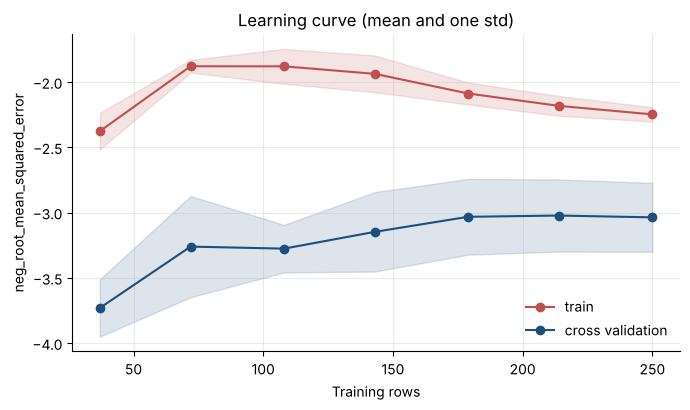

In [9]:
pred = final_model.predict(X_test)
fig = viz.plot_pred_vs_actual(y_test, pred, unit="(miles per gallon)")
save_figure(fig, NOTEBOOK_ID, "pred_vs_actual"); plt.show()
fig = viz.plot_residuals(y_test, pred, unit="(miles per gallon)")
save_figure(fig, NOTEBOOK_ID, "residuals"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()

## 12. Interpretation

Permutation importance shuffles one feature and measures how much the error grows. Correlated features share importance, so read it as a ranking of groups. Check the residual plot for curvature or funnel shapes, which mean the model misses structure or the error variance changes with the prediction.

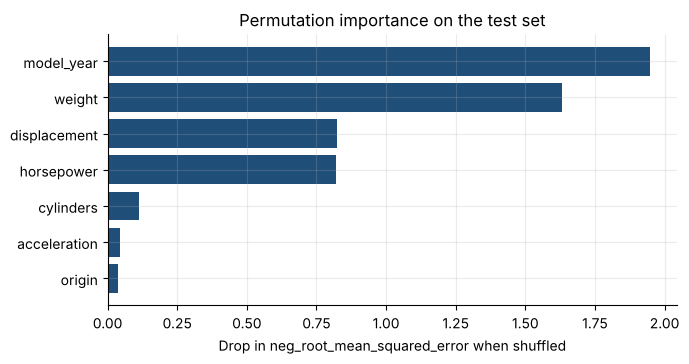

Top features: model_year, weight, displacement, horsepower, cylinders
Largest test errors:


,actual,predicted,abs_error
110,18.0,26.562,8.562
388,44.0,35.569,8.431
361,17.6,23.604,6.004
332,35.0,29.179,5.821
145,24.0,29.570,5.570



Test RMSE: 2.5821 | baseline RMSE: 7.1847
Cross validation spread (std): 0.2882. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Speed versus GradientBoosting

Time both on the same data.

In [11]:
import time
from sklearn.ensemble import GradientBoostingRegressor
for name, m in [("HistGB", HistGradientBoostingRegressor(max_iter=200, random_state=SEED)), ("GradientBoosting", GradientBoostingRegressor(n_estimators=200, random_state=SEED))]:
    start = time.time(); m.fit(Xtr, y_train); print(f"{name}: {time.time() - start:.2f} s, val RMSE {np.sqrt(np.mean((m.predict(Xva) - y_val.values) ** 2)):.3f}")

HistGB: 0.05 s, val RMSE 3.231
GradientBoosting: 0.07 s, val RMSE 3.165


### Experiment 2: Native missing values

Hide 15 percent of horsepower values and let the model handle it, compared with median imputation.

In [12]:
from sklearn.model_selection import cross_val_score
def cv_rmse(model, X_data=None, y_data=None):
    scores = cross_val_score(model, X_data if X_data is not None else X_trainval,
                             y_data if y_data is not None else y_trainval,
                             cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std(ddof=1)
rng = np.random.default_rng(SEED)
X_hole = X_trainval.copy()
X_hole.loc[rng.random(len(X_hole)) < 0.15, "horsepower"] = np.nan
native = cv_rmse(HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, random_state=SEED), X_hole)
imputed = cv_rmse(make_model_pipeline(X_hole, HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, random_state=SEED), scale=False), X_hole)
print(f"native NaN handling: {native[0]:.2f} +- {native[1]:.2f}")
print(f"median imputation: {imputed[0]:.2f} +- {imputed[1]:.2f}")

native NaN handling: 2.89 +- 0.33
median imputation: 2.87 +- 0.34


### Experiment 3: Early stopping

Let the model stop itself and see how many iterations it keeps.

In [13]:
m = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.05, early_stopping=True, validation_fraction=0.2, n_iter_no_change=20, random_state=SEED).fit(Xtr, y_train)
print("iterations used:", m.n_iter_, "of 1000")

iterations used: 111 of 1000


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Add one more feature or remove one and explain the change using cross validation.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Ke et al. report large speedups from histogram methods on big data. Our dataset has under 400 rows, so any timing difference here only demonstrates the mechanism, not their scale results.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Tune with random search over leaf size and regularisation and compare with LightGBM directly.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Histograms speed up split search.
- NaN handling is built in.
- Early stopping saves tuning work.

**Use cases.** Medium to large tabular data.

**Limitations.** Less transparent than a single tree.

**Recommended next notebook.** Logistic Regression (classification).

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.